# Анализ пространственно-временной динамики ареала лебедей в Северной Америке

---

## Цель проекта

Определить, наблюдается ли статистически значимое смещение ареала лебедей в Северной Америке, и выявить, различается ли это смещение в разных географических зонах. Оценить влияние внешних факторов (температура, плотность населения) на пространственное распределение птиц.

---

## Задачи проекта

1. Загрузить и очистить данные о наблюдениях за лебедями.
2. Добавить внешние данные (плотность населения и температура по штатам и провинциям).
3. Провести кластерный анализ для выделения географических зон.
4. Учесть сезонность и другие искажающие факторы.
5. Провести статистический анализ: оценить тренды, сравнить виды и сезоны.
6. Построить визуализации (не менее 4 графиков).
7. Сформулировать выводы.

---

# Описание датасетов

---

## 1. `short.csv` — наблюдения за лебедями

**Источник:** GBIF (Global Biodiversity Information Facility)

**Объём:** ~3.5 млн записей

| Столбец | Тип | Описание |
|---------|-----|----------|
| `gbifID` | int | Уникальный идентификатор наблюдения |
| `basisOfRecord` | str | Тип записи |
| `recordedBy` | str | Наблюдатель |
| `eventDate` | str | Дата наблюдения |
| `year` | int | Год |
| `month` | int | Месяц |
| `day` | int | День |
| `countryCode` | str | Код страны |
| `stateProvince` | str | Штат / провинция |
| `locality` | str | Локация |
| `decimalLatitude` | float | Широта |
| `decimalLongitude` | float | Долгота |
| `coordinateUncertaintyInMeters` | float | — |
| `coordinatePrecision` | float | — |
| `infraspecificEpithet` | float | — |
| `taxonRank` | str | Ранг таксона |
| `datasetKey` | str | Идентификатор источника |
| `elevation` | float | — |
| `elevationAccuracy` | float | — |
| `depth` | float | — |
| `depthAccuracy` | float | — |
| `species` | str | Вид |

**Виды в датасете:**
- `Cygnus olor` — лебедь-шипун
- `Cygnus buccinator` — лебедь-трубач
- `Cygnus columbianus` — американский тундровый лебедь
- `Cygnus atratus` — чёрный лебедь
- `Cygnus cygnus` — лебедь-кликун
- `Cygnus melancoryphus` — черношейный лебедь

---

## 2. `US_CA.csv` — плотность населения

**Объём:** 69 записей

| Столбец | Тип | Описание |
|---------|-----|----------|
| `state_province` | str | Название штата / провинции |
| `land_area` | float | Площадь, км² |
| `density_per` | float | Плотность населения, чел/км² |

---

## 3. `us_state_temperatures.csv` — температуры США

**Объём:** ~26 868 записей

| Столбец | Тип | Описание |
|---------|-----|----------|
| `state` | str | Название штата |
| `year` | int | Год |
| `month` | int | Месяц |
| `avg_temp_f` | float | Температура, °F |
| `avg_temp_c` | float | Температура, °C |

---

## 4. `canada_temperatures.csv` — температуры Канады

**Объём:** 6 864 записи

| Столбец | Тип | Описание |
|---------|-----|----------|
| `state_province` | str | Название провинции |
| `year` | int | Год |
| `month` | int | Месяц |
| `avg_temp_c` | float | Температура, °C |



# Критерии оценки

| № | Критерий | Баллы |
|---|----------|-------|
| 1 | Данные загружены и очищены | 1 |
| 2 | Обрезка по годам и фильтрация выполнены | 1 |
| 3 | Обогащение данными (плотность, температура) выполнено | 1 |
| 4 | Сезонная фильтрация и разбиение на периоды выполнены | 1 |
| 5 | Кластерный анализ выполнен, выделено 5 кластеров | 1 |
| 6 | Построено минимум 4 визуализации | 1 |
| 7 | Применён хотя бы один статистический тест | 1 |
| 8 | Выводы сформулированы | 1 |
| 9 | Датасет сохранён в CSV | 1 |
| **Итого** | | **9** |

---

# Формат итогового отчёта

Ноутбук должен содержать:

1. Введение (цель, задачи, данные).
2. Предобработку данных (код + краткие пояснения).
3. Обогащение данными.
4. Кластерный анализ.
5. Статистический анализ.
6. Визуализации.
7. Выводы (что удалось выяснить, ограничения).

---

# Предобработка и обогащение данных
---

## 1. Загрузка библиотек

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import linregress, kruskal, mannwhitneyu, pearsonr, spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.formula.api import ols

sns.set_style('whitegrid')

## 2. Загрузка данных

In [2]:
data = pd.read_csv('short.csv')

In [3]:
def data_info(data):
    """
    Функция для изучения первичной информации о датасете
    (первые 5 строк, общая информация, описательная статистика, 
    пропуски, явные дубликаты)
    Parameters:
        data (pd.DataFrame): датафрейм с данными
    """
    display(data.head())
    print('________'*10)
    display(data.info())
    print('________'*10)
    display(data.describe().T)
    print('________'*10)
    display('Количество пропусков:', data.isna().sum())
    print('________'*10)
    display('Количество явных дубликатов:', data.duplicated().sum())
    print('________'*10)

In [4]:
data_info(data)

,gbifID,basisOfRecord,recordedBy,eventDate,year,month,day,countryCode,stateProvince,locality,...,coordinateUncertaintyInMeters,coordinatePrecision,infraspecificEpithet,taxonRank,datasetKey,elevation,elevationAccuracy,depth,depthAccuracy,species
0,938888072,HUMAN_OBSERVATION,obsr137539,2008-01-19,2008,1,19,US,Massachusetts,Provincetown Harbor--boat ramp on Commercial S...,...,NaN,NaN,NaN,SPECIES,4fa7b334-ce0d-4e88-aaae-2e0c138d049e,NaN,NaN,NaN,NaN,Cygnus olor
1,3511818940,HUMAN_OBSERVATION,obsr902368,2021-01-23,2021,1,23,US,Massachusetts,South Hadley Canal Park,...,NaN,NaN,NaN,SPECIES,4fa7b334-ce0d-4e88-aaae-2e0c138d049e,NaN,NaN,NaN,NaN,Cygnus olor
2,5474067204,HUMAN_OBSERVATION,obsr440493,2024-03-21,2024,3,21,US,New York,Marshlands Conservancy,...,NaN,NaN,NaN,SPECIES,4fa7b334-ce0d-4e88-aaae-2e0c138d049e,NaN,NaN,NaN,NaN,Cygnus olor
3,3264353040,HUMAN_OBSERVATION,obsr305952,2020-05-28,2020,5,28,CA,Ontario,Port Franks private beach (restricted access),...,NaN,NaN,NaN,SPECIES,4fa7b334-ce0d-4e88-aaae-2e0c138d049e,NaN,NaN,NaN,NaN,Cygnus olor
4,3630533474,HUMAN_OBSERVATION,obsr1312860,2021-09-09,2021,9,9,CA,Ontario,Niagara-on-the-Lake--Outlet Collection ponds,...,NaN,NaN,NaN,SPECIES,4fa7b334-ce0d-4e88-aaae-2e0c138d049e,NaN,NaN,NaN,NaN,Cygnus buccinator


________________________________________________________________________________
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3489498 entries, 0 to 3489497
Data columns (total 22 columns):
 #   Column                         Dtype  
---  ------                         -----  
 0   gbifID                         int64  
 1   basisOfRecord                  object 
 2   recordedBy                     object 
 3   eventDate                      object 
 4   year                           int64  
 5   month                          int64  
 6   day                            int64  
 7   countryCode                    object 
 8   stateProvince                  object 
 9   locality                       object 
 10  decimalLatitude                float64
 11  decimalLongitude               float64
 12  coordinateUncertaintyInMeters  float64
 13  coordinatePrecision            float64
 14  infraspecificEpithet           float64
 15  taxonRank                      object 
 16  datasetKe

None

________________________________________________________________________________


,count,mean,std,min,25%,50%,75%,max
gbifID,3489498.0,3.446432e+09,1.584873e+09,1.328315e+08,2.115309e+09,3.574132e+09,4.750371e+09,5.716379e+09
year,3489498.0,2.018632e+03,5.663563e+00,1.980000e+03,2.016000e+03,2.020000e+03,2.022000e+03,2.024000e+03
month,3489498.0,5.882609e+00,3.664935e+00,1.000000e+00,3.000000e+00,5.000000e+00,1.000000e+01,1.200000e+01
day,3489498.0,1.532224e+01,8.790792e+00,1.000000e+00,8.000000e+00,1.500000e+01,2.300000e+01,3.100000e+01
decimalLatitude,3489498.0,4.299199e+01,4.599620e+00,1.797686e+01,4.073554e+01,4.239741e+01,4.404779e+01,7.428330e+01
decimalLongitude,3489498.0,-8.759845e+01,1.818097e+01,-1.766638e+02,-9.106323e+01,-8.155203e+01,-7.526015e+01,1.783604e+02
coordinateUncertaintyInMeters,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
coordinatePrecision,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
infraspecificEpithet,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elevation,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


...

gbifID                                 0
basisOfRecord                          0
recordedBy                             0
eventDate                              0
year                                   0
month                                  0
day                                    0
countryCode                            0
stateProvince                          0
locality                               4
decimalLatitude                        0
decimalLongitude                       0
coordinateUncertaintyInMeters    3489498
coordinatePrecision              3489498
infraspecificEpithet             3489498
taxonRank                              0
datasetKey                             0
elevation                        3489498
elevationAccuracy                3489498
depth                            3489498
depthAccuracy                    3489498
species                                0
dtype: int64

________________________________________________________________________________


'Количество явных дубликатов:'

np.int64(0)

________________________________________________________________________________


## 3. Удаление пустых столбцов

In [5]:
short_data = data.dropna(axis=1, how='all')

In [6]:
short_data = short_data.drop(columns='locality')

In [7]:
short_data.columns

Index(['gbifID', 'basisOfRecord', 'recordedBy', 'eventDate', 'year', 'month',
       'day', 'countryCode', 'stateProvince', 'decimalLatitude',
       'decimalLongitude', 'taxonRank', 'datasetKey', 'species'],
      dtype='object')

Колонки только с пустыми значениями удалены, удален столбец locality.

## 4. Переименование столбцов в snake_case

In [8]:
def camel_to_snake(name):
    '''Преобразует CamelCase в snake_case.'''
    s1 = re.sub('(.)([A-Z][a-z]+)', r'\1_\2', name)
    return re.sub('([a-z0-9])([A-Z])', r'\1_\2', s1).lower()

In [9]:
short_data.columns = short_data.columns.map(camel_to_snake)
print(short_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3489498 entries, 0 to 3489497
Data columns (total 14 columns):
 #   Column             Dtype  
---  ------             -----  
 0   gbif_id            int64  
 1   basis_of_record    object 
 2   recorded_by        object 
 3   event_date         object 
 4   year               int64  
 5   month              int64  
 6   day                int64  
 7   country_code       object 
 8   state_province     object 
 9   decimal_latitude   float64
 10  decimal_longitude  float64
 11  taxon_rank         object 
 12  dataset_key        object 
 13  species            object 
dtypes: float64(2), int64(4), object(8)
memory usage: 372.7+ MB
None


In [10]:
short_data['state_province'] = short_data['state_province'].str.lower()

## 5. Преобразование типа event_date

In [11]:
short_data['event_date'] = pd.to_datetime(short_data['event_date'])
short_data['event_date'].sample(10)

2069082   2021-03-08
2920305   2019-04-15
2766050   2021-08-14
1946926   2018-03-25
2340350   2021-03-11
1257138   2023-05-17
883690    2002-04-15
2785969   2023-09-13
1000339   2022-04-21
1296059   2024-11-13
Name: event_date, dtype: datetime64[ns]

## 6. Фильтрация данных


In [12]:
# Оставляем три вида птиц из двух стран для анализа

birds_to_analyze = ['Cygnus olor', 'Cygnus buccinator', 'Cygnus columbianus']
short_filtered = short_data[short_data['species'].isin(birds_to_analyze)]

countries_to_analyze = ['US', 'CA']
short_filtered = short_filtered[short_filtered['country_code'].isin(countries_to_analyze)]

print(short_filtered['species'].unique())
print(short_filtered['country_code'].unique())

['Cygnus olor' 'Cygnus buccinator' 'Cygnus columbianus']
['US' 'CA']


In [13]:
# Фильтруем данные по координатам

short_us_ca = short_filtered[
    short_filtered['decimal_latitude'].between(25, 75) &
    short_filtered['decimal_longitude'].between(-170, -35)
]

In [14]:
# Удаляем столбцы с единственным уникальным значением

short_us_ca.nunique()

gbif_id              3477414
basis_of_record            1
recorded_by           133457
event_date             16041
year                      45
month                     12
day                       31
country_code               2
state_province            62
decimal_latitude      326558
decimal_longitude     331078
taxon_rank                 1
dataset_key                1
species                    3
dtype: int64

In [15]:
short_us_ca = short_us_ca.drop(columns=['basis_of_record', 'taxon_rank', 'dataset_key'])
short_us_ca.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3477414 entries, 0 to 3489497
Data columns (total 11 columns):
 #   Column             Dtype         
---  ------             -----         
 0   gbif_id            int64         
 1   recorded_by        object        
 2   event_date         datetime64[ns]
 3   year               int64         
 4   month              int64         
 5   day                int64         
 6   country_code       object        
 7   state_province     object        
 8   decimal_latitude   float64       
 9   decimal_longitude  float64       
 10  species            object        
dtypes: datetime64[ns](1), float64(2), int64(4), object(4)
memory usage: 318.4+ MB


Для анализа оставлены три вида птиц, из Канады и США, данные очищены по координатам, из датасета убраны столбцы с единственным значением.

## 7. Обрезка по годам

In [16]:
# Оставляем данные до 2023 года включительно

short_total = short_us_ca[short_us_ca['year'] <= 2023]


In [17]:
data_info(short_total)

,gbif_id,recorded_by,event_date,year,month,day,country_code,state_province,decimal_latitude,decimal_longitude,species
0,938888072,obsr137539,2008-01-19,2008,1,19,US,massachusetts,42.041756,-70.19348,Cygnus olor
1,3511818940,obsr902368,2021-01-23,2021,1,23,US,massachusetts,42.222797,-72.60885,Cygnus olor
3,3264353040,obsr305952,2020-05-28,2020,5,28,CA,ontario,43.231647,-81.91111,Cygnus olor
4,3630533474,obsr1312860,2021-09-09,2021,9,9,CA,ontario,43.155900,-79.17696,Cygnus buccinator
5,3244141543,obsr58975,2020-05-29,2020,5,29,CA,yukon territory,60.424446,-134.24268,Cygnus buccinator


________________________________________________________________________________
<class 'pandas.core.frame.DataFrame'>
Index: 3033096 entries, 0 to 3489497
Data columns (total 11 columns):
 #   Column             Dtype         
---  ------             -----         
 0   gbif_id            int64         
 1   recorded_by        object        
 2   event_date         datetime64[ns]
 3   year               int64         
 4   month              int64         
 5   day                int64         
 6   country_code       object        
 7   state_province     object        
 8   decimal_latitude   float64       
 9   decimal_longitude  float64       
 10  species            object        
dtypes: datetime64[ns](1), float64(2), int64(4), object(4)
memory usage: 277.7+ MB


None

________________________________________________________________________________


,count,mean,min,25%,50%,75%,max,std
gbif_id,3033096.0,3145703666.203218,132832247.0,2048403041.75,3243505865.5,4345737788.5,5716379133.0,1476004218.804882
event_date,3033096,2018-04-18 08:55:56.560822016,1980-01-01 00:00:00,2016-03-06 00:00:00,2019-12-16 00:00:00,2022-02-18 00:00:00,2023-12-31 00:00:00,NaN
year,3033096.0,2017.849435,1980.0,2016.0,2019.0,2022.0,2023.0,5.643267
month,3033096.0,5.891506,1.0,3.0,5.0,10.0,12.0,3.675337
day,3033096.0,15.342548,1.0,8.0,15.0,23.0,31.0,8.775666
decimal_latitude,3033096.0,42.966959,25.253895,40.713825,42.37029,44.004025,74.2833,4.591902
decimal_longitude,3033096.0,-87.6003,-169.60693,-90.93563,-81.29714,-75.16586,-52.694126,18.118202


...

gbif_id              0
recorded_by          0
event_date           0
year                 0
month                0
day                  0
country_code         0
state_province       0
decimal_latitude     0
decimal_longitude    0
species              0
dtype: int64

________________________________________________________________________________


'Количество явных дубликатов:'

np.int64(0)

________________________________________________________________________________


In [18]:
print(f'Размер исходного датасета: {len(data)} строк.')
print(f'Размер нового датасета: {len(short_total)} строк.')
print(f'Количество удаленных строк: {len(data) - len(short_total)}.')

Размер исходного датасета: 3489498 строк.
Размер нового датасета: 3033096 строк.
Количество удаленных строк: 456402.


## 8. Загрузка внешних данных


In [19]:
df_us_ca = pd.read_csv('US_CA.csv')
us_temperatures = pd.read_csv('us_state_temperatures.csv')
ca_temperatures = pd.read_csv('canada_temperatures.csv')

In [20]:
df_us_ca['state_province'].unique()

array(['District of Columbia', 'New Jersey', 'Rhode Island',
       'Puerto Rico', 'Massachusetts', 'Guam[4]', 'Connecticut',
       'U.S. Virgin Islands[4]', 'Maryland', 'American Samoa[4]',
       'Delaware', 'Florida', 'New York', 'Pennsylvania', 'Ohio',
       'Northern Mariana Islands[4]', 'California', 'Illinois', 'Hawaii',
       'North Carolina', 'Virginia', 'Georgia', 'Indiana',
       'South Carolina', 'Michigan', 'Tennessee', 'New Hampshire',
       'Washington', 'Texas', 'Kentucky', 'Wisconsin', 'Louisiana',
       'Alabama', 'Missouri', 'West Virginia', 'Minnesota', 'Vermont',
       'Arizona', 'Mississippi', 'Oklahoma', 'Arkansas', 'Iowa',
       'Colorado', 'Maine', 'Oregon', 'Utah', 'Kansas', 'Nevada',
       'Nebraska', 'Idaho', 'New Mexico', 'South Dakota', 'North Dakota',
       'Montana', 'Wyoming', 'Alaska', 'Ontario', 'Quebec',
       'British Columbia', 'AB', 'Manitoba', 'Saskatchewan',
       'Nova Scotia', 'New Brunswick', 'Newfoundland and Labrador',
       'P

In [21]:
short_total['state_province'].unique()

array(['massachusetts', 'ontario', 'yukon territory', 'michigan',
       'virginia', 'british columbia', 'indiana', 'new jersey',
       'delaware', 'missouri', 'new york', 'ohio', 'illinois', 'alaska',
       'pennsylvania', 'north carolina', 'montana', 'connecticut',
       'north dakota', 'tennessee', 'wisconsin', 'florida', 'idaho',
       'alberta', 'oregon', 'california', 'maryland', 'minnesota',
       'washington', 'south carolina', 'nunavut', 'utah', 'quebec',
       'saskatchewan', 'kentucky', 'rhode island', 'manitoba', 'vermont',
       'iowa', 'wyoming', 'new mexico', 'kansas', 'colorado', 'nebraska',
       'texas', 'south dakota', 'arizona', 'nevada', 'arkansas',
       'new hampshire', 'louisiana', 'georgia', 'oklahoma',
       'northwest territories', 'mississippi', 'west virginia', 'alabama',
       'maine', 'nova scotia', 'district of columbia',
       'newfoundland and labrador', 'new brunswick'], dtype=object)

In [22]:
# Приводим названия штатов и провинций к едидному формату

# Убираем цифры
df_us_ca['state_province'] = df_us_ca['state_province'].str.replace(r'\[\d+\]', '', regex=True).str.strip()

# Убираем несоответствия с основным датасетом
state_mapping = {
    'AB': 'Alberta',
    'Yukon': 'Yukon Territory'
}
df_us_ca['state_province'] = df_us_ca['state_province'].replace(state_mapping)

# Приводим названия к нижнему регистру и единому формату
df_us_ca['state_province'] = df_us_ca['state_province'].str.lower()


In [23]:
df_us_ca['state_province'].unique()

array(['district of columbia', 'new jersey', 'rhode island',
       'puerto rico', 'massachusetts', 'guam', 'connecticut',
       'u.s. virgin islands', 'maryland', 'american samoa', 'delaware',
       'florida', 'new york', 'pennsylvania', 'ohio',
       'northern mariana islands', 'california', 'illinois', 'hawaii',
       'north carolina', 'virginia', 'georgia', 'indiana',
       'south carolina', 'michigan', 'tennessee', 'new hampshire',
       'washington', 'texas', 'kentucky', 'wisconsin', 'louisiana',
       'alabama', 'missouri', 'west virginia', 'minnesota', 'vermont',
       'arizona', 'mississippi', 'oklahoma', 'arkansas', 'iowa',
       'colorado', 'maine', 'oregon', 'utah', 'kansas', 'nevada',
       'nebraska', 'idaho', 'new mexico', 'south dakota', 'north dakota',
       'montana', 'wyoming', 'alaska', 'ontario', 'quebec',
       'british columbia', 'alberta', 'manitoba', 'saskatchewan',
       'nova scotia', 'new brunswick', 'newfoundland and labrador',
       'prince e

In [24]:
# Приводим датасеты температур к единому виду

data_info(us_temperatures)

,state,year,month,avg_temp_f,avg_temp_c
0,Alabama,1980,1,46.7,8.166667
1,Alabama,1980,2,42.7,5.944444
2,Alabama,1980,3,52.6,11.444444
3,Alabama,1980,4,60.6,15.888889
4,Alabama,1980,5,70.2,21.222222


________________________________________________________________________________
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26868 entries, 0 to 26867
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   state       26868 non-null  object 
 1   year        26868 non-null  int64  
 2   month       26868 non-null  int64  
 3   avg_temp_f  26868 non-null  float64
 4   avg_temp_c  26868 non-null  float64
dtypes: float64(2), int64(2), object(1)
memory usage: 1.0+ MB


None

________________________________________________________________________________


,count,mean,std,min,25%,50%,75%,max
year,26868.0,2002.083519,12.962470,1980.000000,1991.000000,2002.000000,2013.000000,2024.000000
month,26868.0,6.500000,3.452117,1.000000,3.750000,6.500000,9.250000,12.000000
avg_temp_f,26868.0,52.302676,17.817926,-12.800000,39.100000,53.700000,67.000000,89.200000
avg_temp_c,26868.0,11.279264,9.898848,-24.888889,3.944444,12.055556,19.444444,31.777778


...

state         0
year          0
month         0
avg_temp_f    0
avg_temp_c    0
dtype: int64

________________________________________________________________________________


'Количество явных дубликатов:'

np.int64(0)

________________________________________________________________________________


In [25]:
data_info(ca_temperatures)

,state_province,year,month,avg_temp_c
0,Alberta,1980,1,-15.833060
1,Alberta,1980,2,-8.911123
2,Alberta,1980,3,-6.203974
3,Alberta,1980,4,7.940524
4,Alberta,1980,5,11.229850


________________________________________________________________________________
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6864 entries, 0 to 6863
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   state_province  6864 non-null   object 
 1   year            6864 non-null   int64  
 2   month           6864 non-null   int64  
 3   avg_temp_c      6864 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 214.6+ KB


None

________________________________________________________________________________


,count,mean,std,min,25%,50%,75%,max
year,6864.0,2001.500000,12.699350,1980.000000,1990.750000,2001.500000,2012.250000,2023.000000
month,6864.0,6.500000,3.452304,1.000000,3.750000,6.500000,9.250000,12.000000
avg_temp_c,6864.0,1.819538,12.367163,-35.335392,-6.703482,3.418385,12.379625,22.071422


...

state_province    0
year              0
month             0
avg_temp_c        0
dtype: int64

________________________________________________________________________________


'Количество явных дубликатов:'

np.int64(0)

________________________________________________________________________________


In [26]:
# Приводим названия столбцов и названия территорий к единой форме
us_temperatures = us_temperatures.rename(columns={'state': 'state_province'})
state_mapping = {
    'yukon': 'yukon territory'
}
ca_temperatures['state_province'] = ca_temperatures['state_province'].replace(state_mapping)

# Приводим названия к нижнему регистру
us_temperatures['state_province'] = us_temperatures['state_province'].str.lower()
ca_temperatures['state_province'] = ca_temperatures['state_province'].str.lower()

# Убираем в Американском датасете столбец с температурой по фаренгейту
us_temperatures = us_temperatures.drop(columns=['avg_temp_f'])

In [27]:
# Объединяем два датасета в один

temperatures_us_ca = pd.concat([us_temperatures, ca_temperatures], ignore_index=True)
temperatures_us_ca.sample(10)

# Приводим названия штатов и провинций к варианту как в основном датасете
temperatures_us_ca['state_province'] = (
    temperatures_us_ca['state_province'].str.replace('_', ' ', regex=False)
)
temperatures_us_ca.sample(10)

,state_province,year,month,avg_temp_c
22341,tennessee,2007,10,17.333333
4169,delaware,2012,6,22.722222
28023,manitoba,1988,4,2.784591
8960,kentucky,2017,9,20.166667
11460,michigan,2001,1,-4.777778
14179,nebraska,2002,8,22.777778
30454,nunavut,2014,11,-17.629115
29490,newfoundland and labrador,2022,7,15.487972
18252,ohio,1982,1,-6.777778
11761,minnesota,1981,2,-7.111111


Названия штатов приведены к единому формату, датасеты с температурой приведены к единому формату, объединены в единый датасет.

## 9. Сезонная фильтрация

In [28]:
# Оставляем в основном датасете только данные за зиму и лето

short_total = short_total[short_total['month'].isin([12, 1, 2, 6, 7, 8])]
short_total['month'].unique()

array([ 1, 12,  2,  8,  7,  6])

In [29]:
# Добавляем столбец обозначающий период - зимовка и гнездование

short_total['period_type'] = short_total['month'].apply(
    lambda x: 1 if x in [12, 1, 2] else 2
)

## 10. Разбивка на временные периоды

In [30]:
def get_period(year):
    """
    Функция для определения периода по году
    """
    if 1980 <= year <= 1988:
        return '1_1980-1988'
    elif 1989 <= year <= 1997:
        return '2_1989-1997'
    elif 1998 <= year <= 2006:
        return '3_1998-2006'
    elif 2007 <= year <= 2015:
        return '4_2007-2015'
    else:
        return '5_2016-2023'

In [31]:
short_total['time_period'] = short_total['year'].apply(get_period)

Данные сегментированы на 5 временных периодов.

## 11. Округление координат и удаление дубликатов

In [32]:
# Округляем данные по координатам до целых

short_total['decimal_latitude'] = short_total['decimal_latitude'].round()
short_total['decimal_longitude'] = short_total['decimal_longitude'].round()

In [33]:
len(short_total)

1289670

In [34]:
short_total = short_total.drop_duplicates(subset=['year', 'period_type', 'decimal_longitude', 'decimal_latitude', 'species'])

In [35]:
len(short_total)

33095

In [36]:
# Объединяем основной датасет с информацией о плотности населения

short_total.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33095 entries, 0 to 3489412
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   gbif_id            33095 non-null  int64         
 1   recorded_by        33095 non-null  object        
 2   event_date         33095 non-null  datetime64[ns]
 3   year               33095 non-null  int64         
 4   month              33095 non-null  int64         
 5   day                33095 non-null  int64         
 6   country_code       33095 non-null  object        
 7   state_province     33095 non-null  object        
 8   decimal_latitude   33095 non-null  float64       
 9   decimal_longitude  33095 non-null  float64       
 10  species            33095 non-null  object        
 11  period_type        33095 non-null  int64         
 12  time_period        33095 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(5), object(5)
memory usa

In [37]:
df_us_ca.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69 entries, 0 to 68
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   state_province  69 non-null     object 
 1   land_area       69 non-null     float64
 2   density_per     69 non-null     float64
dtypes: float64(2), object(1)
memory usage: 1.7+ KB


In [38]:
short_total = short_total.merge(
    df_us_ca,
    on='state_province',
    how='left'
)

In [39]:
short_total.isna().sum()

gbif_id              0
recorded_by          0
event_date           0
year                 0
month                0
day                  0
country_code         0
state_province       0
decimal_latitude     0
decimal_longitude    0
species              0
period_type          0
time_period          0
land_area            0
density_per          0
dtype: int64

Удалены дубликаты, округлены значения координат, а также основной датасет дополнен инфомрацией о плотности населения.

## 12. Объединение с температурой

In [40]:
# Объединяем основной датасет с информацией о температуре
short_total = short_total.merge(
    temperatures_us_ca,
    on=['state_province', 'year', 'month'],
    how='left'
)

In [41]:
short_total.isna().sum()

gbif_id              0
recorded_by          0
event_date           0
year                 0
month                0
day                  0
country_code         0
state_province       0
decimal_latitude     0
decimal_longitude    0
species              0
period_type          0
time_period          0
land_area            0
density_per          0
avg_temp_c           5
dtype: int64

In [42]:
short_total.loc[
    short_total['avg_temp_c'].isna(),
    'state_province'
].unique()

array(['district of columbia'], dtype=object)

По округу Колумбия нет информации в таблице температур, но есть два ближайших соседа, по которым есть данные - Вирджиния и Мэрилэнд. Заполним пропуски ближайшим географическим соседом - Мэрилендом, так как у Колумбии с Вирджинией есть граница по реке, что может сильнее повлиять на разницу температур. 

In [43]:
maryland_temp = temperatures_us_ca[
    temperatures_us_ca['state_province'] == 'maryland'
][['year', 'month', 'avg_temp_c']]

maryland_temp = maryland_temp.rename(
    columns={'avg_temp_c': 'maryland_temp'}
)

short_total = short_total.merge(
    maryland_temp,
    on=['year', 'month'],
    how='left'
)

In [44]:
mask = (
    (short_total['state_province'] == 'district of columbia') &
    (short_total['avg_temp_c'].isna())
)
short_total.loc[mask, 'avg_temp_c'] = short_total.loc[mask, 'maryland_temp']
short_total = short_total.drop(columns='maryland_temp')

In [45]:
short_total.loc[
    short_total['state_province'] == 'district of columbia',
    ['year', 'month', 'avg_temp_c']
]

,year,month,avg_temp_c
4655,2015,7,24.388889
4881,2015,12,9.222222
26099,2002,8,25.111111
27977,2004,6,21.555556
30260,2005,7,25.333333


In [46]:
data_info(short_total)

,gbif_id,recorded_by,event_date,year,month,day,country_code,state_province,decimal_latitude,decimal_longitude,species,period_type,time_period,land_area,density_per,avg_temp_c
0,938888072,obsr137539,2008-01-19,2008,1,19,US,massachusetts,42.0,-70.0,Cygnus olor,1,4_2007-2015,20202.0,347.0,-2.111111
1,3511818940,obsr902368,2021-01-23,2021,1,23,US,massachusetts,42.0,-73.0,Cygnus olor,1,5_2016-2023,20202.0,347.0,-1.777778
2,1708517102,obsr46830,2016-01-03,2016,1,3,US,michigan,43.0,-85.0,Cygnus buccinator,1,5_2016-2023,146435.0,69.0,-5.388889
3,5349334195,obsr6752262,2023-01-19,2023,1,19,US,virginia,38.0,-77.0,Cygnus columbianus,1,5_2016-2023,102279.0,85.0,5.944444
4,2035949122,obsr379975,2017-01-21,2017,1,21,CA,british columbia,50.0,-117.0,Cygnus buccinator,1,5_2016-2023,944735.0,5.4,-3.185258


________________________________________________________________________________
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33095 entries, 0 to 33094
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   gbif_id            33095 non-null  int64         
 1   recorded_by        33095 non-null  object        
 2   event_date         33095 non-null  datetime64[ns]
 3   year               33095 non-null  int64         
 4   month              33095 non-null  int64         
 5   day                33095 non-null  int64         
 6   country_code       33095 non-null  object        
 7   state_province     33095 non-null  object        
 8   decimal_latitude   33095 non-null  float64       
 9   decimal_longitude  33095 non-null  float64       
 10  species            33095 non-null  object        
 11  period_type        33095 non-null  int64         
 12  time_period        33095 non-null  

None

________________________________________________________________________________


,count,mean,min,25%,50%,75%,max,std
gbif_id,33095.0,2609596009.148633,132832291.0,1166949141.0,2188475257.0,4206436906.0,5716358346.0,1688466000.704958
event_date,33095,2010-10-28 02:57:15.854358528,1980-01-01 00:00:00,2004-08-07 12:00:00,2013-07-20 00:00:00,2019-02-20 00:00:00,2023-12-31 00:00:00,NaN
year,33095.0,2010.373712,1980.0,2004.0,2013.0,2019.0,2023.0,10.567621
month,33095.0,5.932346,1.0,2.0,6.0,8.0,12.0,4.028002
day,33095.0,15.0685,1.0,7.0,15.0,23.0,31.0,8.970981
decimal_latitude,33095.0,44.801692,25.0,40.0,43.0,47.0,74.0,8.440188
decimal_longitude,33095.0,-100.384711,-169.0,-119.0,-92.0,-82.0,-53.0,22.892316
period_type,33095.0,1.405137,1.0,1.0,1.0,2.0,2.0,0.490926
land_area,33095.0,442013.832949,158.0,125920.0,206232.0,640330.46,1877778.53,471967.315483
density_per,33095.0,62.87721,0.02,6.7,35.0,86.0,4297.0,100.580522


...

gbif_id              0
recorded_by          0
event_date           0
year                 0
month                0
day                  0
country_code         0
state_province       0
decimal_latitude     0
decimal_longitude    0
species              0
period_type          0
time_period          0
land_area            0
density_per          0
avg_temp_c           0
dtype: int64

________________________________________________________________________________


'Количество явных дубликатов:'

np.int64(0)

________________________________________________________________________________


## 13. Сохранение датасета

In [47]:
short_total.to_csv("data_seasonal_enriched.csv", index=False, encoding="utf-8")

## 14. Финальная проверка

In [48]:
print(f'Итоговый датасет содержит {len(short_total)} записей.')

Итоговый датасет содержит 33095 записей.


In [49]:
# Распределение по периодам

short_total['time_period'].value_counts(ascending=True)

time_period
1_1980-1988     1685
2_1989-1997     2920
3_1998-2006     5317
4_2007-2015     9732
5_2016-2023    13441
Name: count, dtype: int64

In [50]:
# Распределение по видам

short_total['species'].value_counts(ascending=True)

species
Cygnus olor           10146
Cygnus columbianus    11069
Cygnus buccinator     11880
Name: count, dtype: int64

In [51]:
# Средняя температура по сезонам

short_total.groupby('period_type')['avg_temp_c'].mean()

period_type
1    -0.595584
2    17.449024
Name: avg_temp_c, dtype: float64

In [52]:
# Средняя широта по сезонам

short_total.groupby('period_type')['decimal_latitude'].mean()

period_type
1    41.775334
2    49.245301
Name: decimal_latitude, dtype: float64

### Общие выводы по датасету
* Итоговый датасет содержит 33095 записей. 
* По периодам он распределен неравномерно - больше всего наблюдений в 5 периоде (2016-2023 года), меньше всего в 1 периоде (1980-1988). 
* По видам лебедей наблюдения распределены практически равномерно, тем не менее меньше всего наблюдений по виду Cygnus olor.
* Средняя температура по сезонам равна -0.6 для зимовки и +17.4 в период гнездования.
* Средняя широта наблюдений в период гнездования 49.25, в период зимовки 41.78.

---

# Анализ данных
---

## 15. Кластерный анализ

In [53]:
# Выдляем пять кластеров

coords = short_total[['decimal_latitude', 'decimal_longitude']].values
coords_scaled = StandardScaler().fit_transform(coords)

linkage_matrix = linkage(coords_scaled, method='ward')
short_total['cluster'] = fcluster(linkage_matrix, t=5, criterion='maxclust')

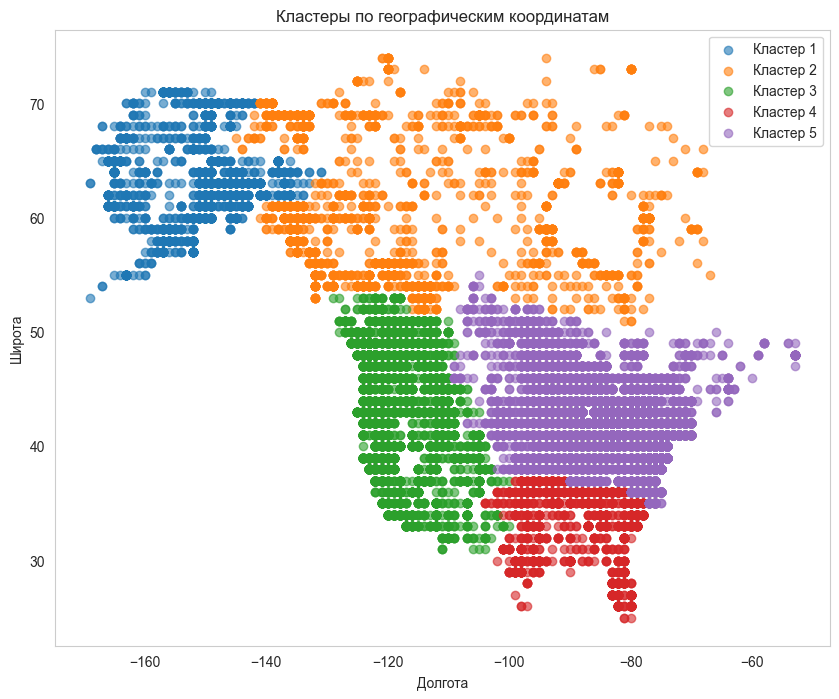

In [54]:
plt.figure(figsize=(10, 8))

for cluster in sorted(short_total['cluster'].unique()):
    data = short_total[short_total['cluster'] == cluster]
    
    plt.scatter(
        data['decimal_longitude'],
        data['decimal_latitude'],
        label=f'Кластер {cluster}',
        alpha=0.6
    )

plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.title('Кластеры по географическим координатам')
plt.legend()
plt.grid()
plt.show()

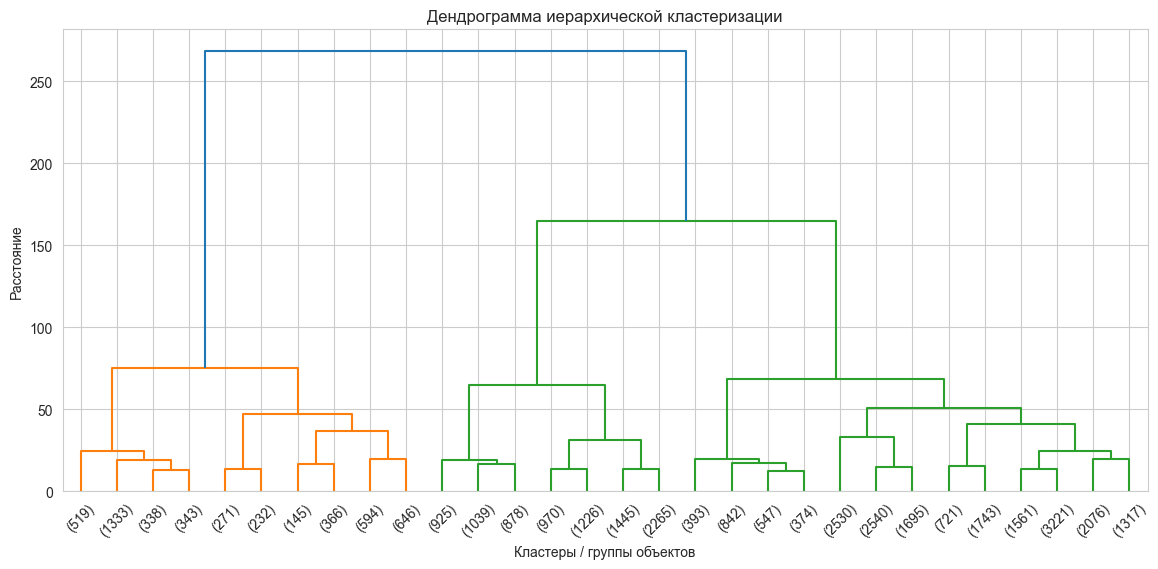

In [55]:
plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Дендрограмма иерархической кластеризации')
plt.xlabel('Кластеры / группы объектов')
plt.ylabel('Расстояние')
plt.show()

## 16. Описательная статистика по кластерам

In [56]:
short_total.groupby('cluster')['decimal_latitude'].describe()

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
1,2533.0,63.214370,3.675449,53.0,61.0,63.0,65.0,71.0
2,2254.0,60.519965,5.698779,51.0,56.0,60.0,65.0,74.0
3,8748.0,43.753315,4.939414,31.0,40.0,44.0,48.0,53.0
4,2156.0,32.925788,3.111697,25.0,30.0,34.0,35.0,37.0
5,17404.0,42.084348,3.013351,35.0,40.0,42.0,44.0,55.0


In [57]:
short_total.groupby('cluster')['avg_temp_c'].describe()

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
1,2533.0,9.479868,6.143974,-24.888889,9.944444,10.666667,11.777778,17.321394
2,2254.0,9.487787,8.988504,-26.094975,6.859702,12.185309,15.397875,21.435308
3,8748.0,4.965103,8.595296,-20.928010,-1.444444,1.722222,10.000000,28.333333
4,2156.0,11.968898,8.788866,-4.388889,5.763889,9.166667,16.611111,31.222222
5,17404.0,6.182120,11.657132,-22.288940,-3.500000,1.888889,19.049627,29.111111


In [58]:
short_total['cluster'].value_counts(ascending=True)

cluster
4     2156
2     2254
1     2533
3     8748
5    17404
Name: count, dtype: int64

* Средняя температура по кластерам различается между собой: наибольшая средняя температура в 4 кластере - почти +12, наименьшая в 3 кластере - около +5,  в 1 и 2 кластерах она равна примерно +9.5, в 5 кластере средняяя температура равна примерно +6.2. Хоть в каждом кластере средняя температура положительная, температура также опускается и ниже нуля, в некоторых кластерах до -26 (минимальные значения), и также высоко поднимается, в некоторых кластерах до +30 (макисмальные значения).
* По средней широте мы видим что кластеры примерно равномерно покрывают географическую территорию исследования.
* По количеству наблюдений равномерно распределены 1, 2 и 4 кластер, у них же меньше всего наблюдений. Больше всего наблюдений "забрал" 5 кластер - 17404.

## 17. Линейная регрессия по кластерам

In [59]:
results = []

for cluster in short_total['cluster'].unique():
    
    data = short_total[short_total['cluster'] == cluster]
    
    slope, intercept, r_value, p_value, std_err = linregress(
        data['year'],
        data['decimal_latitude']
    )
    
    results.append({
        'cluster': cluster,
        'slope': slope,
        'p_value': p_value,
        'R2': r_value**2
    })

results_df = pd.DataFrame(results)
display(results_df)


,cluster,slope,p_value,R2
0,5,0.028735,6.865944e-40,0.009991
1,3,-0.009658,4.098040e-02,0.000477
2,4,-0.018942,9.251157e-03,0.003140
3,2,-0.144655,2.197677e-38,0.071833
4,1,0.002454,7.424916e-01,0.000043


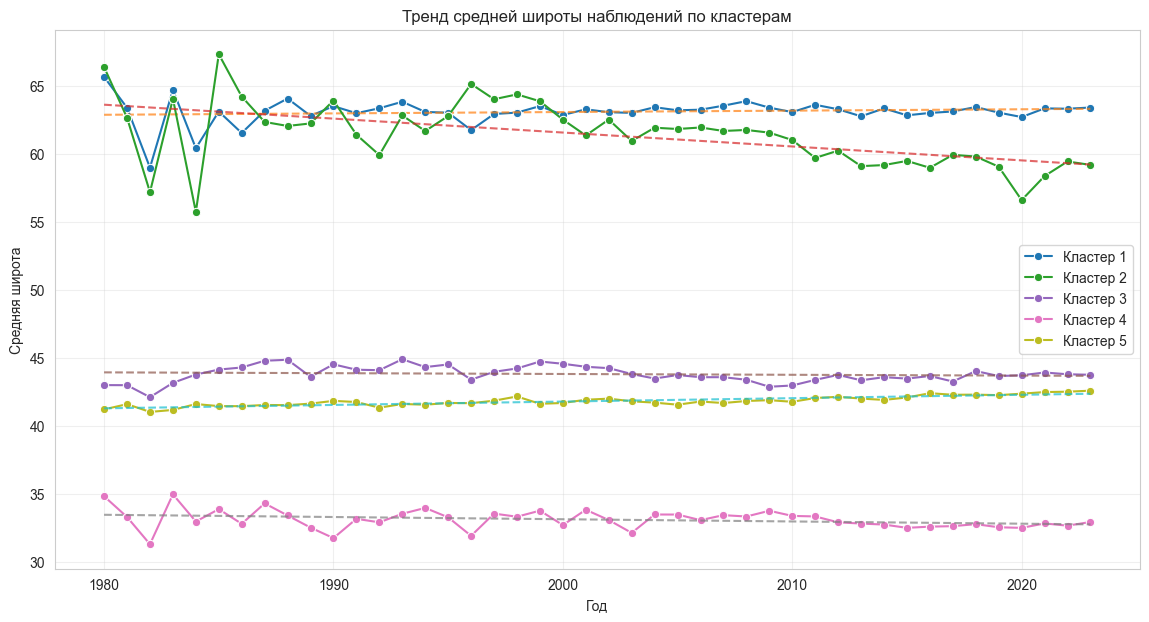

In [60]:
# Средняя широта по годам для каждого кластера
trend_data = (
    short_total
    .groupby(['cluster', 'year'])['decimal_latitude']
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 7))

for cluster in sorted(trend_data['cluster'].unique()):
    
    data = trend_data[trend_data['cluster'] == cluster]
    
    # Фактическая средняя широта по годам
    sns.lineplot(
        data=data,
        x='year',
        y='decimal_latitude',
        marker='o',
        label=f'Кластер {cluster}'
    )
    
    # Линия регрессии
    slope, intercept, r_value, p_value, std_err = linregress(
        data['year'],
        data['decimal_latitude']
    )
    
    x = data['year']
    y_pred = intercept + slope * x
    
    plt.plot(
        x,
        y_pred,
        linestyle='--',
        alpha=0.7
    )

plt.xlabel('Год')
plt.ylabel('Средняя широта')
plt.title('Тренд средней широты наблюдений по кластерам')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

* Динамика широты различается по кластерам.
* В кластерах 2, 3, 4 наблюдения смещаются на юг, в кластерах 1, 5 - на север.
* Хоть мы и применяем линейную модель, стоит обратить внимание, что на мигарцию птиц может влиять не только время, что будет проверено в пунктах ниже.

## 18. Корреляционный анализ

In [61]:
# Корреляция широты и плотности населения  по Пирсону

r, p = pearsonr(short_total['density_per'], short_total['decimal_latitude'])
print(f"Пирсон: r = {r:.3f}, p = {p:.4f}")

Пирсон: r = -0.329, p = 0.0000


In [62]:
# Корреляция широты и плотности населения по Спирмену

rho, p = spearmanr(short_total['density_per'], short_total['decimal_latitude'])
print(f"Спирмен: ρ = {rho:.3f}, p = {p:.4f}")

Спирмен: ρ = -0.693, p = 0.0000


In [63]:
# Корреляция широты и температуры по Пирсону в целом
r, p = pearsonr(short_total['avg_temp_c'], short_total['decimal_latitude'])
print(f"Пирсон: r = {r:.3f}, p = {p:.4f}")

Пирсон: r = 0.036, p = 0.0000


In [64]:
# Корреляция широты и температуры по Пирсону по сезонам

results_pearsonr = []

for period in short_total['period_type'].unique():
    
    data = short_total[short_total['period_type'] == period]
    
    r, p = pearsonr(
        data['avg_temp_c'], 
        data['decimal_latitude']
        )
    
    results_pearsonr.append({
        'period_type': period,
        'r': round(r, 3),
        'p': round(p, 4)
    })

results_pearsonr_df = pd.DataFrame(results_pearsonr)
print(results_pearsonr_df)

   period_type      r    p
0            1 -0.637  0.0
1            2 -0.875  0.0


In [65]:
# Корреляция широты и температуры по Спирмену в целом

rho, p = spearmanr(short_total['avg_temp_c'], short_total['decimal_latitude'])
print(f"Спирмен: ρ = {rho:.3f}, p = {p:.4f}")

Спирмен: ρ = -0.016, p = 0.0031


In [66]:
# Корреляция широты и температуры по Спирмену по сезонам

results_spearmanr = []

for period in short_total['period_type'].unique():
    
    data = short_total[short_total['period_type'] == period]
    
    r, p = spearmanr(
        data['avg_temp_c'], 
        data['decimal_latitude']
        )
    
    results_spearmanr.append({
        'period_type': period,
        'r': round(r, 3),
        'p': round(p, 4)
    })

results_spearmanr_df = pd.DataFrame(results_spearmanr)
print(results_spearmanr_df)

   period_type      r    p
0            1 -0.598  0.0
1            2 -0.869  0.0


* При разделении данных на сехоны видно отрицаительную корреляцию для зимовки коэффициент Пирсона составил −0,637, для периода гнездования −0,875. 
* Объединенный анализ показывает зависимость температуры от широты по каждому сезону (что в целом логично, что температура отличается в разных широтах)

## 19. Сравнение групп (Kruskal-Wallis, Mann-Whitney)

In [67]:
# Сравниваем виды по широте

groups = [short_total[short_total['species'] == sp]['decimal_latitude'] for sp in short_total['species'].unique()]
stat, p = kruskal(*groups)
print(f"Kruskal-Wallis для видов по широте: H = {stat:.2f}, p = {p:.4f}")

Kruskal-Wallis для видов по широте: H = 4528.09, p = 0.0000


In [68]:
# Сравниваем виды по температуре

groups = [short_total[short_total['species'] == sp]['avg_temp_c'] for sp in short_total['species'].unique()]
stat, p = kruskal(*groups)
print(f"Kruskal-Wallis для видов по температуре: H = {stat:.2f}, p = {p:.4f}")

Kruskal-Wallis для видов по температуре: H = 1502.13, p = 0.0000


In [69]:
# Сравниваем сезоны по широте

winter = short_total[short_total['period_type'] == 1]['decimal_latitude']
breeding = short_total[short_total['period_type'] == 2]['decimal_latitude']
stat, p = mannwhitneyu(winter, breeding, alternative='two-sided')
print(f"Mann-Whitney для сезонов: p = {p:.4f}, U = {stat}")

Mann-Whitney для сезонов: p = 0.0000, U = 72489238.5


In [70]:
# Попарные сравнения видов

g1 = short_total[short_total['species'] == 'Cygnus olor']['decimal_latitude']

g2 = short_total[short_total['species'] == 'Cygnus buccinator']['decimal_latitude']

stat, p = mannwhitneyu(g1, g2, alternative='two-sided')

print(f"Cygnus olor vs Cygnus buccinator: p = {p:.4f}")

Cygnus olor vs Cygnus buccinator: p = 0.0000


In [71]:
g1 = short_total[short_total['species'] == 'Cygnus olor']['decimal_latitude']

g2 = short_total[short_total['species'] == 'Cygnus columbianus']['decimal_latitude']

stat, p = mannwhitneyu(g1, g2, alternative='two-sided')

print(f"Cygnus olor vs Cygnus columbianus: p = {p:.4f}")

Cygnus olor vs Cygnus columbianus: p = 0.0000


In [72]:
g1 = short_total[short_total['species'] == 'Cygnus buccinator']['decimal_latitude']

g2 = short_total[short_total['species'] == 'Cygnus columbianus']['decimal_latitude']

stat, p = mannwhitneyu(g1, g2, alternative='two-sided')

print(f"Cygnus buccinator vs Cygnus columbianus: p = {p:.4f}")

Cygnus buccinator vs Cygnus columbianus: p = 0.0000


* Критерий Крускала - Уоллиса показывает различие между видами и по широте наблюдений и по температуре.
* Распределение по широте в период зимовки и гнездования различаются между собой.
* Попарные сравнения видов показали статистически значимые различия по широте для всех трех пар (p < 0.001 во всех случаях).

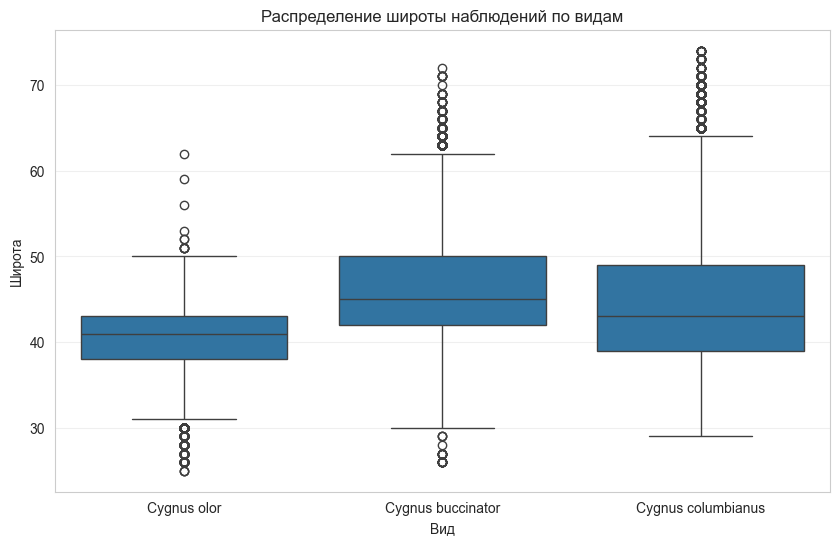

In [73]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=short_total,
    x='species',
    y='decimal_latitude'
)

plt.xlabel('Вид')
plt.ylabel('Широта')
plt.title('Распределение широты наблюдений по видам')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [74]:
short_total.groupby('species')['decimal_latitude'].describe()

,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Cygnus buccinator,11880.0,47.145455,7.483678,26.0,42.0,45.0,50.0,72.0
Cygnus columbianus,11069.0,46.318638,10.398316,29.0,39.0,43.0,49.0,74.0
Cygnus olor,10146.0,40.402425,4.532364,25.0,38.0,41.0,43.0,62.0


* Cygnus olor в основном расположен на более низких широтах.
* Cygnus buccinator расположен в основном на более высоких широтах.
* У Cygnus columbianus самый широкий ареал обитания, захватывающий в том числе широты двух других изучаемых видов.

## 20. Множественная регрессия

In [75]:
X = short_total[['year', 'avg_temp_c', 'density_per']]
X = sm.add_constant(X)
y = short_total['decimal_latitude']

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       decimal_latitude   R-squared:                       0.113
Model:                            OLS   Adj. R-squared:                  0.113
Method:                 Least Squares   F-statistic:                     1410.
Date:                Wed, 30 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:30:24   Log-Likelihood:            -1.1556e+05
No. Observations:               33095   AIC:                         2.311e+05
Df Residuals:                   33091   BIC:                         2.312e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         119.9945      8.375     14.328      

Множественная линейная регрессия показала статистически значимую связь широты с годом, средней температурой и плотностью населения (p < 0.001). Однако, в дальнейших исследованиях следует проверить мультиколлинеарность в модели.

## 22. Выводы

#### Наблюдается ли смещение ареала? Различается ли оно по кластерам?
В результате проведенного исследования мы увидели **смещение широты наблюдений по времени**, но они неоднородные. В разных кластерах наблюдаются разные тренды: в кластерах 1 и 5 мы видим положительный тренд - смещение в сторону высоких широт, в кластерах 2, 3, 4 мы видим отрицательный тренд - наблюдения смещаются вниз. Отметим, что пространственная структура данных неоднородна: изменения широты зависят от выделенной географического кластера (некоторые кластеры изначально охватывают больше широт и имеют больше наблюдений).

#### Какие различия между видами и сезонами?
Cygnus buccinator самый северный лебедь из взятых для анализа, медианная широта его обитания - 45, самый южный - Cygnus olor, медианная широта - 41. Cygnus columbianus расположился по середине, медианная широта - 43, но стоит отметить что общих охват его наблюдений расположился практически по всем широтам, в которых наблюдаются и другие виды. 

Между зимовкой и гнездованием обнаружено статистически значимое различие по широте, а также связь широты и температуры различается при разделении по сезонам.

#### Какие ограничения есть у анализа?

Во-первых, отметим, что количество наблюдений ощутимо различается по годам и по выделенным кластерам. Это может искажать результаты анализа для малочисленных кластеров в сравнении с теми, в которых наблюдений больше. 
Во-вторых, более давние наблюдения, скорее всего менее точные, чем современные, мы рассматриваем довольно продолжительный промежуток времени, технологии изучения ареалов обитания птиц за это время изменялись. 
В-третьих, поскольку вначале анализа мы округляли данные по координатам, некоторые наблюдения могли значительно сместиться и повлиять на результаты. Сюда же отметим и заполнение данных по температуре соседним регионом, они могут быть близки к реальным, но для более точного исследования стоит найти актуальную информацию по округу.


#### Возможные направления развития исследования (личный интерес исследователя)
* Для дальнейшего изучения стоит найти больше данных за ранние годы изучения, чтобы сбалансировать количество наблюдений.
* Предположительно, стоит поэксперементировать с кластерами и посмотреть, что изменится в анализе, если сформировать их с использованием других методов.
* На изменения ареала обитания лебедей могут влиять ареалы обитания других животных, можно изучить как они повлияют друг на друга.
* Изучение пространственного распределения лебедей до и после крупных стихийных бедствий (наводнения, пожары и пр.).